1. Menu-driven calculator

In [ ]:
def add(a, b):
    return a + b

def subtract(a, b):
    return a - b

def multiply(a, b):
    return a * b

def divide(a, b):
    return a / b

while True:
    print("\n1. Add")
    print("2. Subtract")
    print("3. Multiply")
    print("4. Divide")
    print("5. Exit")
    choice = input("Enter your choice: ").strip()

    if choice == "5":
        print("Calculator closed.")
        break

    if choice not in ("1", "2", "3", "4"):
        print("Invalid choice.")
        continue

    try:
        a = float(input("Enter first number: "))
        b = float(input("Enter second number: "))
    except ValueError:
        print("Enter numbers only.")
        continue

    if choice == "1":
        print("Answer:", add(a, b))
    elif choice == "2":
        print("Answer:", subtract(a, b))
    elif choice == "3":
        print("Answer:", multiply(a, b))
    else:
        if b == 0:
            print("Cannot divide by zero.")
        else:
            print("Answer:", divide(a, b))


1. Add
2. Subtract
3. Multiply
4. Divide
5. Exit
Enter your choice: 1
Enter first number: 6
Enter second number: 4
Answer: 10.0

1. Add
2. Subtract
3. Multiply
4. Divide
5. Exit
Enter your choice: 4
Enter first number: 56
Enter second number: 4
Answer: 14.0

1. Add
2. Subtract
3. Multiply
4. Divide
5. Exit
Enter your choice: 5
Calculator closed.


2. Fibonacci series

In [ ]:
def fibonacci(n):
    a = 0
    b = 1

    for i in range(n):
        print(a, end=" ")
        a, b = b, a + b

    print()


try:
    n = int(input("Enter number of terms: "))

    if n <= 0:
        print("Enter a positive number.")
    else:
        print("Fibonacci series:")
        fibonacci(n)
except ValueError:
    print("Enter a whole number.")

Enter number of terms: 3
Fibonacci series:
0 1 1 


3. Prime number checking

In [ ]:
def is_prime(n):
    if n < 2:
        return False

    i = 2

    while i * i <= n:
        if n % i == 0:
            return False
        i += 1

    return True


try:
    n = int(input("Enter a number: "))

    if is_prime(n):
        print(n, "is a prime number.")
    else:
        print(n, "is not a prime number.")
except ValueError:
    print("Enter a whole number.")

Enter a number: 7
7 is a prime number.


4. Student records using CSV

In [ ]:
import csv

filename = "students.csv"


def create_file():
    try:
        # "x" creates a new file without overwriting an existing one
        with open(filename, "x", newline="") as file:
            writer = csv.writer(file)
            writer.writerow(["Roll Number", "Name", "Marks"])

        print("File created.")
    except FileExistsError:
        print("File already exists.")


def add_student():
    roll = input("Enter roll number: ").strip()
    name = input("Enter student name: ").strip()

    if roll == "" or name == "":
        print("Roll number and name cannot be empty.")
        return

    try:
        marks = float(input("Enter marks out of 100: "))
    except ValueError:
        print("Enter valid marks.")
        return

    if not 0 <= marks <= 100:
        print("Marks must be between 0 and 100.")
        return

    # Check whether the roll number is already saved
    try:
        with open(filename, "r", newline="") as file:
            reader = csv.reader(file)
            next(reader, None)

            for row in reader:
                if row and row[0] == roll:
                    print("Roll number already exists.")
                    return
    except FileNotFoundError:
        create_file()

    with open(filename, "a", newline="") as file:
        writer = csv.writer(file)
        writer.writerow([roll, name, marks])

    print("Record added.")


def read_students():
    try:
        with open(filename, "r", newline="") as file:
            reader = csv.reader(file)
            next(reader, None)

            found = False
            print("\nRoll Number | Name | Marks")

            for row in reader:
                if row:
                    print(row[0], "|", row[1], "|", row[2])
                    found = True

            if not found:
                print("No records added yet.")
    except FileNotFoundError:
        print("Create the file first.")


while True:
    print("\n1. Create file")
    print("2. Add student")
    print("3. Read records")
    print("4. Exit")

    choice = input("Enter your choice: ").strip()

    try:
        if choice == "1":
            create_file()
        elif choice == "2":
            add_student()
        elif choice == "3":
            read_students()
        elif choice == "4":
            print("Program closed.")
            break
        else:
            print("Invalid choice.")
    except OSError:
        print("Unable to access the file.")


1. Create file
2. Add student
3. Read records
4. Exit
Enter your choice: 1
File created.

1. Create file
2. Add student
3. Read records
4. Exit
Enter your choice: 2
Enter roll number: 10362
Enter student name: Atharva Patankar
Enter marks out of 100: 98
Record added.

1. Create file
2. Add student
3. Read records
4. Exit
Enter your choice: 3

Roll Number | Name | Marks
10362 | Atharva Patankar | 98.0

1. Create file
2. Add student
3. Read records
4. Exit
Enter your choice: 4
Program closed.


# **Program 2 - Data Ananlysis and Visulization**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

dataset = Path("Wholesale customers data.csv")
if not dataset.exists():
    from google.colab import files
    uploaded = files.upload()
    dataset = Path(next(name for name in uploaded if name.lower().endswith(".csv")))
df = pd.read_csv(dataset)

sns.set_theme(style="whitegrid")

display(df.head())

Saving Wholesale customers data.csv to Wholesale customers data (1).csv


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print("Rows and columns:", df.shape)
print("\nColumn names:", df.columns.tolist())

df.info()

display(df.tail())
display(df.describe())

Rows and columns: (440, 8)

Column names: ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [4]:
products = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicassen"
]

print("Missing values before cleaning:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values before cleaning:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate rows: 0


In [6]:
df[products] = df[products].fillna(df[products].median())
df = df.dropna(subset=["Channel", "Region"]).copy()

print("\nMissing values after cleaning:")
print(df.isna().sum())


Missing values after cleaning:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


# Multiple columns

In [8]:
display(df[["Milk", "Grocery"]].head())

,Milk,Grocery
0,9656,7561
1,9810,9568
2,8808,7684
3,1196,4221
4,5410,7198


Selection by position

In [9]:
display(df.iloc[:5, :4])

,Channel,Region,Fresh,Milk
0,2,3,12669,9656
1,2,3,7057,9810
2,2,3,6353,8808
3,1,3,13265,1196
4,2,3,22615,5410


Selection by index labels and column names

In [10]:
display(df.loc[df.index[:5], ["Channel", "Fresh", "Milk"]])

,Channel,Fresh,Milk
0,2,12669,9656
1,2,7057,9810
2,2,6353,8808
3,1,13265,1196
4,2,22615,5410


Customers spending more than 20,000 on Fresh products

In [11]:
display(df[df["Fresh"] > 20000].head())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
4,2,3,22615,5410,7198,3915,1777,5185
12,2,3,31714,12319,11757,287,3881,2931
13,2,3,21217,6208,14982,3095,6707,602
14,2,3,24653,9465,12091,294,5058,2168
22,1,3,31276,1917,4469,9408,2381,4334


Filter using query

In [12]:
display(df.query("Milk > 10000 and Grocery > 10000").head())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
9,2,3,6006,11093,18881,1159,7425,2098
12,2,3,31714,12319,11757,287,3881,2931
23,2,3,26373,36423,22019,5154,4337,16523
28,2,3,4113,20484,25957,1158,8604,5206
37,2,3,15168,10556,12477,1920,6506,714


Fresh spending in ascending order

In [13]:
display(df.sort_values("Fresh").head())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
338,1,2,3,333,7021,15601,15,550
95,1,3,3,2920,6252,440,223,709
66,1,3,9,1534,7417,175,3468,27
218,2,1,18,7504,15205,1285,4797,6372
96,2,3,23,2616,8118,145,3874,217


Fresh spending in descending order

In [14]:
display(df.sort_values("Fresh", ascending=False).head())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
181,1,3,112151,29627,18148,16745,4948,8550
125,1,3,76237,3473,7102,16538,778,918
284,1,3,68951,4411,12609,8692,751,2406
39,1,3,56159,555,902,10002,212,2916
258,1,1,56083,4563,2124,6422,730,3321


Numerical operations using NumPy

In [15]:
spending = np.array(df[products], dtype=float)

summary = pd.DataFrame({
    "Product": products,
    "Total": np.sum(spending, axis=0),
    "Mean": np.mean(spending, axis=0),
    "Median": np.median(spending, axis=0),
    "Std_dev": np.std(spending, axis=0, ddof=1),
    "Minimum": np.min(spending, axis=0),
    "Maximum": np.max(spending, axis=0)
})

display(summary.round(2))

print("Channel codes:", np.unique(df["Channel"]))
print("Region codes:", np.unique(df["Region"]))

# Total spending for each customer
df["Total_Spending"] = np.sum(spending, axis=1)

highest = np.argmax(df["Total_Spending"].to_numpy())
lowest = np.argmin(df["Total_Spending"].to_numpy())

print("\nCustomer row with highest total spending:")
display(df.iloc[[highest]])

print("Customer row with lowest total spending:")
display(df.iloc[[lowest]])

,Product,Total,Mean,Median,Std_dev,Minimum,Maximum
0,Fresh,5280131.0,12000.30,8504.0,12647.33,3.0,112151.0
1,Milk,2550357.0,5796.27,3627.0,7380.38,55.0,73498.0
2,Grocery,3498562.0,7951.28,4755.5,9503.16,3.0,92780.0
3,Frozen,1351650.0,3071.93,1526.0,4854.67,25.0,60869.0
4,Detergents_Paper,1267857.0,2881.49,816.5,4767.85,3.0,40827.0
5,Delicassen,670943.0,1524.87,965.5,2820.11,3.0,47943.0


Channel codes: [1 2]
Region codes: [1 2 3]

Customer row with highest total spending:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total_Spending
85,2,3,16117,46197,92780,1026,40827,2944,199891.0


Customer row with lowest total spending:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total_Spending
154,1,3,622,55,137,75,7,8,904.0


Addition, subtraction, and multiplication

In [16]:
milk = df["Milk"].to_numpy()
grocery = df["Grocery"].to_numpy()

operations = pd.DataFrame({
    "Milk": milk,
    "Grocery": grocery,
    "Combined": np.add(milk, grocery),
    "Grocery_minus_Milk": np.subtract(grocery, milk),
    "Milk_after_10_percent_increase": np.multiply(milk, 1.10)
})

display(operations.head())

,Milk,Grocery,Combined,Grocery_minus_Milk,Milk_after_10_percent_increase
0,9656,7561,17217,-2095,10621.6
1,9810,9568,19378,-242,10791.0
2,8808,7684,16492,-1124,9688.8
3,1196,4221,5417,3025,1315.6
4,5410,7198,12608,1788,5951.0


Grouping and pivot table

In [17]:
print("Average spending by channel:")
display(df.groupby("Channel")[products].mean().round(2))

print("Average spending by region:")
display(df.groupby("Region")[products].mean().round(2))

print("Channel summary:")
display(
    df.groupby("Channel").agg(
        Customers=("Channel", "size"),
        Average_Total=("Total_Spending", "mean"),
        Total_Spending=("Total_Spending", "sum")
    ).round(2)
)

print("Average grocery spending by region and channel:")
display(
    df.pivot_table(
        values="Grocery",
        index="Region",
        columns="Channel",
        aggfunc="mean"
    ).round(2)
)

Average spending by channel:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Channel,,,,,,
1,13475.56,3451.72,3962.14,3748.25,790.56,1415.96
2,8904.32,10716.50,16322.85,1652.61,7269.51,1753.44


Average spending by region:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Region,,,,,,
1,11101.73,5486.42,7403.08,3000.34,2651.12,1354.9
2,9887.68,5088.17,9218.60,4045.36,3687.47,1159.7
3,12533.47,5977.09,7896.36,2944.59,2817.75,1620.6


Channel summary:


,Customers,Average_Total,Total_Spending
Channel,,,
1,298,26844.19,7999569.0
2,142,46619.23,6619931.0


Average grocery spending by region and channel:


Channel,1,2
Region,,
1,4026.14,18471.94
2,4395.50,16326.32
3,3886.73,15953.81


**Matplotlib bar chart**

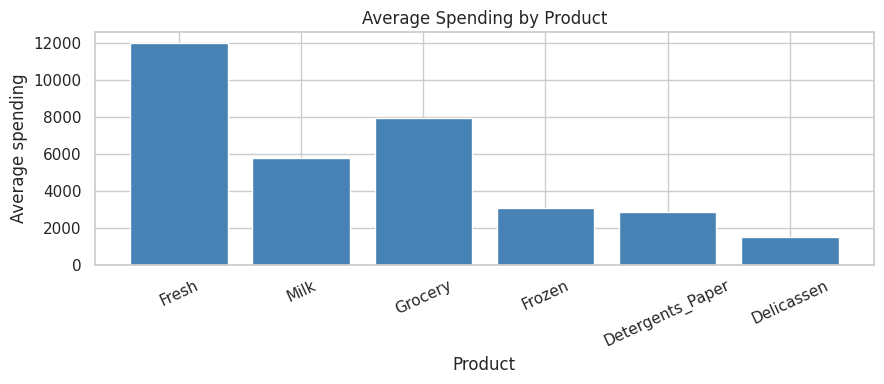

In [18]:
average_spending = df[products].mean()

plt.figure(figsize=(9, 4))
plt.bar(average_spending.index, average_spending.values, color="steelblue")

plt.title("Average Spending by Product")
plt.xlabel("Product")
plt.ylabel("Average spending")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**Seaborn count plot and histogram**

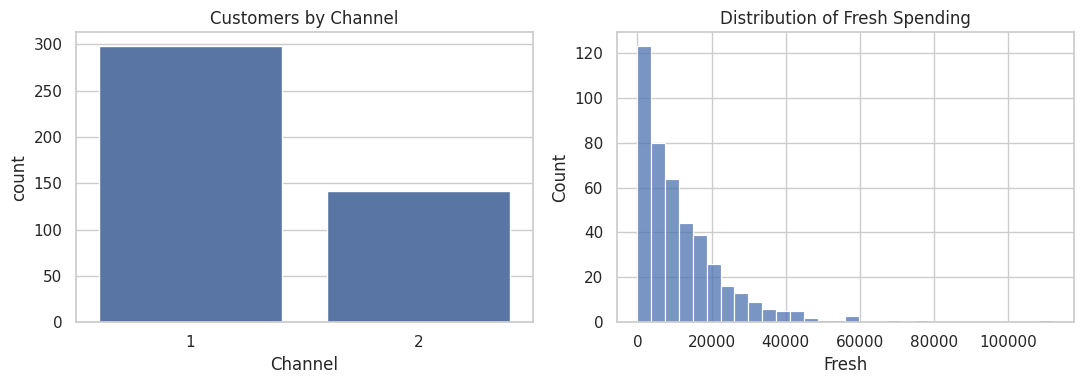

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x="Channel", ax=axes[0])
axes[0].set_title("Customers by Channel")

sns.histplot(data=df, x="Fresh", bins=30, ax=axes[1])
axes[1].set_title("Distribution of Fresh Spending")

plt.tight_layout()
plt.show()

**Scatter plot and box plot**

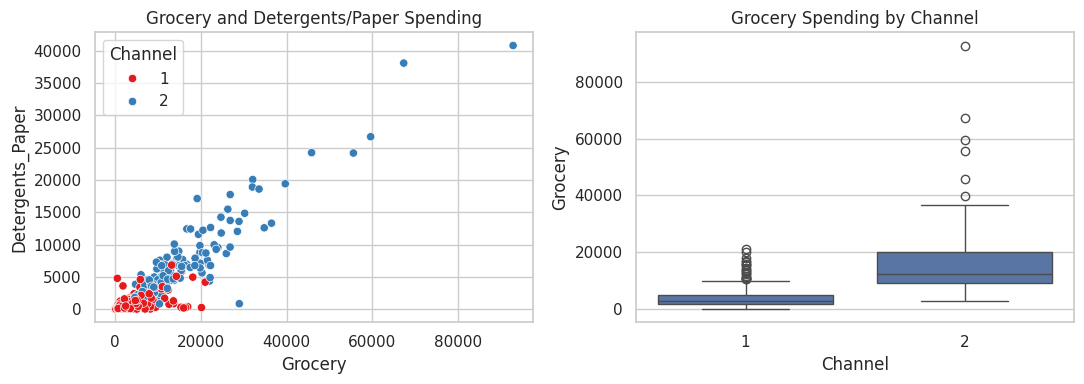

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.scatterplot(
    data=df,
    x="Grocery",
    y="Detergents_Paper",
    hue="Channel",
    palette="Set1",
    ax=axes[0]
)
axes[0].set_title("Grocery and Detergents/Paper Spending")

sns.boxplot(data=df, x="Channel", y="Grocery", ax=axes[1])
axes[1].set_title("Grocery Spending by Channel")

plt.tight_layout()
plt.show()

**Correlation heatmap**

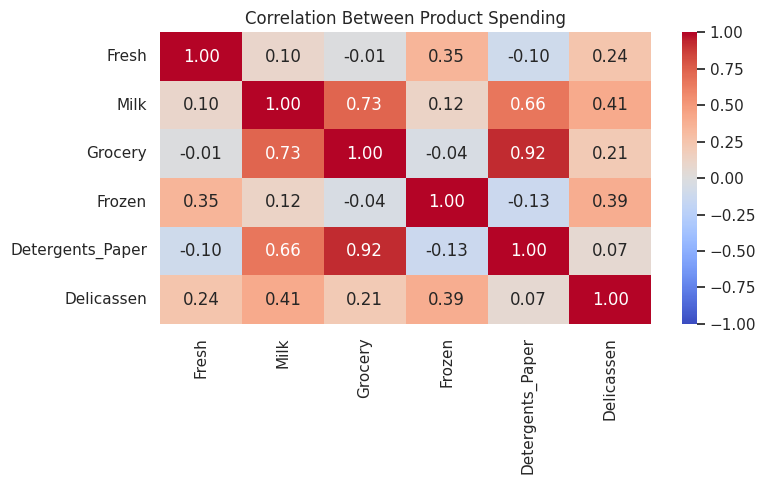

In [21]:
correlation = df[products].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Product Spending")
plt.tight_layout()
plt.show()

# **PROGRAM - 3 **

TensorFlow — Predict total price from item quantity

Predicted price for 7 items: ₹68.49


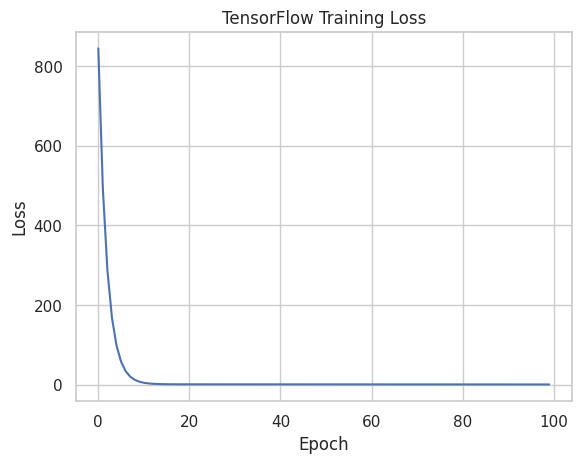

In [25]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

quantity = np.array([[1], [2], [3], [4], [5]], dtype=np.float32)
price = np.array([[10], [20], [30], [40], [50]], dtype=np.float32)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer="sgd", loss="mean_squared_error")

history = model.fit(quantity, price, epochs=100, verbose=0)

prediction = model.predict(
    np.array([[7]], dtype=np.float32), verbose=0
)

print(f"Predicted price for 7 items: ₹{prediction[0][0]:.2f}")

plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("TensorFlow Training Loss")
plt.show()

PyTorch — Predict distance from travel time

Epoch 20, Loss: 1.6158
Epoch 40, Loss: 1.3839
Epoch 60, Loss: 1.2085
Epoch 80, Loss: 1.0554
Epoch 100, Loss: 0.9217

Predicted distance in 7 hours: 67.89 km


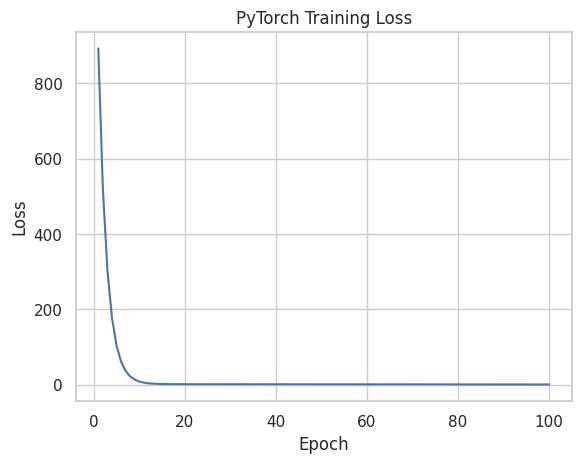

In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

time = torch.tensor([[1.0], [2.0], [3.0], [4.0], [5.0]])
distance = torch.tensor([[10.0], [20.0], [30.0], [40.0], [50.0]])

model = nn.Linear(1, 1)

loss_function = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

loss_values = []

for epoch in range(100):
    prediction = model(time)
    loss = loss_function(prediction, distance)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_values.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1}, Loss: {loss.item():.4f}")

with torch.no_grad():
    result = model(torch.tensor([[7.0]]))

print(f"\nPredicted distance in 7 hours: {result.item():.2f} km")

plt.plot(range(1, 101), loss_values)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PyTorch Training Loss")
plt.show()

Scikit-learn — Recognise handwritten digits

Test accuracy: 98.61%
Actual digit: 5
Predicted digit: 5


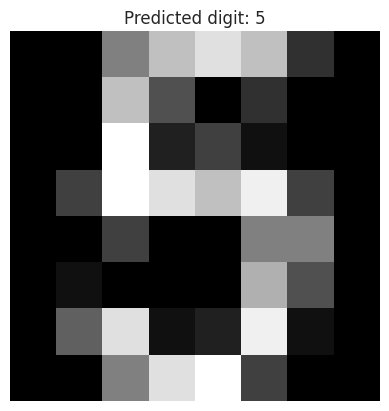

In [27]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

prediction = model.predict(X_test)
accuracy = accuracy_score(y_test, prediction)

print(f"Test accuracy: {accuracy * 100:.2f}%")

sample = X_test[0].reshape(1, -1)
result = model.predict(sample)

print("Actual digit:", y_test[0])
print("Predicted digit:", result[0])

plt.imshow(sample.reshape(8, 8), cmap="gray")
plt.title(f"Predicted digit: {result[0]}")
plt.axis("off")
plt.show()